In [33]:
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.preprocessing import StandardScaler

In [34]:
data = pd.read_csv("../data/curated/merged_data.csv")
data["city_centre"] = data["city_centre"].astype(bool)
data["coastal"] = data["coastal"].astype(bool)
print(list(data.columns))

['property type', 'beds', 'baths', 'parking', 'weekly rent amount', 'postcode', 'distance primary school', 'distance secondary school', 'is closest school good', 'closest university campus', 'distance university campus', 'closest hospital', 'distance to closest hospital', 'offence count 2023', 'estimated resident population (no.) 2011', 'total dwellings (no.) 2017', 'median equivalised total household income (weekly) ($) 2011', 'median weekly household rental payment ($) 2011', 'average family size (no. of persons) 2011', 'estimated resident population (no.) 2016', 'total dwellings (no.) 2019', 'median equivalised total household income (weekly) ($) 2016', 'median weekly household rental payment ($) 2016', 'average family size (no. of persons) 2016', 'estimated resident population (no.) 2021', 'total dwellings (no.) 2021', 'median equivalised total household income (weekly) ($) 2021', 'median weekly household rental payment ($) 2021', 'average family size (no. of persons) 2021', 'dista

In [35]:
data = data.drop(["closest university campus", "closest hospital", "postcode", "closest university campus"], axis=1)
print(len(data))
# remove properites with over 2000 weekly rent 
data = data[data["weekly rent amount"] <= 2000]
print(len(data))

11349
11283


In [36]:
def predict_2023_value(y_values, col_name, x_values = [0,5,10], predict_val = 12): 
    """ 
    Function predicts 2023 value of variable given past data. Assumes linear relationship.
    default value of x_value 0, 5, 10 represents 2011, 2016, 2021. 
    default value of predict_val represents 2023
    """
    # 0, 5, 10 represents 2011, 2016, 2021
    print(y_values)
    print(col_name)
    model = LinearRegression()
    x_values = np.array(x_values).reshape(-1,1)
    y_values = np.array(y_values).reshape(-1,1)
    model.fit(x_values, y_values)
    # 12 represents 2023
    predict_2023 = model.predict(np.array(predict_val).reshape(-1,1))
    return pd.Series({col_name: predict_2023[0][0]})

In [37]:

# predict median equivalised total household income (weekly) ($) 2023
median_income_2023_column = data.apply(lambda x:
    predict_2023_value([x["median equivalised total household income (weekly) ($) 2011"], 
     x["median equivalised total household income (weekly) ($) 2016"],
     x["median equivalised total household income (weekly) ($) 2021"]], 
    "predicted median equivalised total household income (weekly) ($) 2023"), axis=1)

data = pd.concat([data, median_income_2023_column], axis=1)
data[["median equivalised total household income (weekly) ($) 2011", 
     "median equivalised total household income (weekly) ($) 2016",
     "median equivalised total household income (weekly) ($) 2021", 
     "predicted median equivalised total household income (weekly) ($) 2023"]]

data = data.drop(["median equivalised total household income (weekly) ($) 2011", 
     "median equivalised total household income (weekly) ($) 2016",
     "median equivalised total household income (weekly) ($) 2021"], axis=1)

[1089.0, 1265.6666666666667, 1495.0]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalised total household income (weekly) ($) 2023
[628.0, 761.0, 931.0]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalised total household income (weekly) ($) 2023
[509.0, 560.0, 637.0]
predicted median equivalised total household income (weekly) ($) 2023
[575.25, 651.25, 812.75]
predicted median equivalised total household income (weekly) ($) 2023
[697.6, 758.2, 988.8]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalised total household income (weekly) ($) 2023
[1201.0, 1361.0, 1578.5]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalise

In [38]:
# median weekly household rental payment ($) 2023
weekly_rent_2023_column = data.apply(lambda x:
    predict_2023_value([x["median weekly household rental payment ($) 2011"], 
     x["median weekly household rental payment ($) 2016"],
     x["median weekly household rental payment ($) 2021"]], 
    "predicted median weekly household rental payment ($) 2023"), axis=1)

data = pd.concat([data, weekly_rent_2023_column], axis=1)

data[["median weekly household rental payment ($) 2011", 
     "median weekly household rental payment ($) 2016",
     "median weekly household rental payment ($) 2021", 
     "predicted median weekly household rental payment ($) 2023"]]


data = data.drop(["median weekly household rental payment ($) 2011", 
     "median weekly household rental payment ($) 2016",
     "median weekly household rental payment ($) 2021"], axis=1)



[367.0, 420.3333333333333, 466.0]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[271.0, 330.0, 405.0]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[150.0, 180.0, 215.0]
predicted median weekly household rental payment ($) 2023
[255.5, 300.5, 334.5]
predicted median weekly household rental payment ($) 2023
[309.6, 334.4, 372.8]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[360.0, 391.0, 406.5]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[240.0, 28

In [39]:
# predict average family size (no. of persons) 2023
weekly_rent_2023_column = data.apply(lambda x:
    predict_2023_value([x["average family size (no. of persons) 2011"], 
     x["average family size (no. of persons) 2016"],
     x["average family size (no. of persons) 2021"]], 
    "predicted average family size (no. of persons) 2023"), axis=1)

data = pd.concat([data, weekly_rent_2023_column], axis=1)

data[["average family size (no. of persons) 2011", 
     "average family size (no. of persons) 2016",
     "average family size (no. of persons) 2021", 
     "predicted average family size (no. of persons) 2023"]]


data = data.drop(["average family size (no. of persons) 2011", 
     "average family size (no. of persons) 2016",
     "average family size (no. of persons) 2021"], axis=1)


[3.1333333333333333, 3.1333333333333333, 3.033333333333333]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.7, 2.7, 2.7]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.8, 2.8, 2.8]
predicted average family size (no. of persons) 2023
[3.025, 3.025, 3.025]
predicted average family size (no. of persons) 2023
[3.04, 3.04, 2.96]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.45, 2.45, 2.5]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[3.0, 2.9, 2.9]
predicted average family size (no. of persons) 2023
[3.1333333333333333, 3.16666666666666

In [40]:
# predict median weekly household rental payment ($) 2023
weekly_rent_2023_column = data.apply(lambda x:
    predict_2023_value([x["employment ratio 2011"], 
     x["employment ratio 2016"],
     x["employment ratio 2021"]], 
    "predicted employment ratio 2023"), axis=1)

data = pd.concat([data, weekly_rent_2023_column], axis=1)

data[["employment ratio 2011", 
     "employment ratio 2016",
     "employment ratio 2021", 
     "predicted employment ratio 2023"]]


data = data.drop(["employment ratio 2011", 
     "employment ratio 2016",
     "employment ratio 2021"], axis=1)

[0.9559454742700816, 0.9464455426724956, 0.9557909279300024]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted employment ratio 2023
[0.9477260846837428, 0.9499287604315082, 0.96588274263001]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted employment ratio 2023
[0.8778321551567881, 0.8559662899827619, 0.8905660377358491]
predicted employment ratio 2023
[0.9007145859604876, 0.8874827955344854, 0.9205526770293608]
predicted employment ratio 2023
[0.9270833333333334, 0.9057836644591613, 0.9342460070524788]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted employment ratio 2023
[0.9563015558107968, 0.9489363704819276, 0.9572294059137354]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted e

In [41]:
# predict estimated resident population (no.) 2023
weekly_rent_2023_column = data.apply(lambda x:
    predict_2023_value([x["estimated resident population (no.) 2011"], 
     x["estimated resident population (no.) 2016"],
     x["estimated resident population (no.) 2021"]], 
    "predicted estimated resident population (no.) 2023"), axis=1)

data = pd.concat([data, weekly_rent_2023_column], axis=1)

data[["estimated resident population (no.) 2011", 
     "estimated resident population (no.) 2016",
     "estimated resident population (no.) 2021", 
     "predicted estimated resident population (no.) 2023"]]


data = data.drop(["estimated resident population (no.) 2011", 
     "estimated resident population (no.) 2016",
     "estimated resident population (no.) 2021"], axis=1)

[44587.0, 44971.0, 42684.0]
predicted estimated resident population (no.) 2023
[63530.0, 68943.0, 74184.0]
predicted estimated resident population (no.) 2023
[12008.0, 12760.0, 13460.0]
predicted estimated resident population (no.) 2023
[63530.0, 68943.0, 74184.0]
predicted estimated resident population (no.) 2023
[63530.0, 68943.0, 74184.0]
predicted estimated resident population (no.) 2023
[14042.0, 14157.0, 14393.0]
predicted estimated resident population (no.) 2023
[64214.0, 65032.0, 62072.0]
predicted estimated resident population (no.) 2023
[50194.0, 49957.0, 47098.0]
predicted estimated resident population (no.) 2023
[63530.0, 68943.0, 74184.0]
predicted estimated resident population (no.) 2023
[36738.0, 36840.0, 33564.0]
predicted estimated resident population (no.) 2023
[63530.0, 68943.0, 74184.0]
predicted estimated resident population (no.) 2023
[63530.0, 68943.0, 74184.0]
predicted estimated resident population (no.) 2023
[23221.0, 23903.0, 24240.0]
predicted estimated resi

In [42]:
# predict total dwellings (no.) 2017  2023
dwelling_2023_column = data.apply(lambda x:
    predict_2023_value([x["total dwellings (no.) 2017"], 
     x["total dwellings (no.) 2019"],
     x["total dwellings (no.) 2021"]], 
    "predicted total dwellings (no.) 2023", [0,2,4], 6), axis=1)

data = pd.concat([data, dwelling_2023_column], axis=1)

data[["total dwellings (no.) 2017", 
     "total dwellings (no.) 2019",
     "total dwellings (no.) 2021", 
     "predicted total dwellings (no.) 2023"]]


data = data.drop(["total dwellings (no.) 2017", 
     "total dwellings (no.) 2019",
     "total dwellings (no.) 2021"], axis=1)

[17239.0, 17551.0, 17800.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[8219.0, 8551.0, 8829.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[6945.0, 6961.0, 7010.0]
predicted total dwellings (no.) 2023
[23194.0, 23885.0, 24313.0]
predicted total dwellings (no.) 2023
[18968.0, 19363.0, 19908.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[20419.0, 20978.0, 21725.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[10134.0, 10599.0, 10780.0]
predicted total dwellings (no.) 2023
[19833.0, 20217.0, 20457.0]
predicted total dwellings (no.) 2023
[19833.0, 20217.0, 20457.0]
predicted total dwellings (no.) 2023
[23656.0, 23927.0, 24272.0]
pre

In [43]:
print(list(data.columns))

['property type', 'beds', 'baths', 'parking', 'weekly rent amount', 'distance primary school', 'distance secondary school', 'is closest school good', 'distance university campus', 'distance to closest hospital', 'offence count 2023', 'distance train station', 'total_supermarkets', 'major_supermarkets', 'city_centre', 'closest_city_centre', 'coastal', 'closest_cc_dist', 'dist_to_melb', 'predicted median equivalised total household income (weekly) ($) 2023', 'predicted median weekly household rental payment ($) 2023', 'predicted average family size (no. of persons) 2023', 'predicted employment ratio 2023', 'predicted estimated resident population (no.) 2023', 'predicted total dwellings (no.) 2023']


In [44]:
data.isna().any()

property type                                                            False
beds                                                                     False
baths                                                                    False
parking                                                                  False
weekly rent amount                                                       False
distance primary school                                                  False
distance secondary school                                                False
is closest school good                                                   False
distance university campus                                               False
distance to closest hospital                                             False
offence count 2023                                                       False
distance train station                                                   False
total_supermarkets                                  

In [45]:
# drop columns with missing values
data = data.drop(["total_supermarkets", "major_supermarkets"], axis=1)

In [46]:
list(data.columns[data.isna().any()])

['closest_city_centre', 'closest_cc_dist', 'dist_to_melb']

In [47]:
print(len(data))
data = data.dropna()
print(len(data))

11283
11173


In [48]:
data[data.isna().any(axis=1)]

,property type,beds,baths,parking,weekly rent amount,distance primary school,distance secondary school,is closest school good,distance university campus,distance to closest hospital,...,closest_city_centre,coastal,closest_cc_dist,dist_to_melb,predicted median equivalised total household income (weekly) ($) 2023,predicted median weekly household rental payment ($) 2023,predicted average family size (no. of persons) 2023,predicted employment ratio 2023,predicted estimated resident population (no.) 2023,predicted total dwellings (no.) 2023


In [49]:
# save data for linear regression before one-hot-encoding
data.to_csv("../data/curated/data_XGBoost_before_onehotencode.csv", index=False)

In [50]:
# one hot encode categorical variables
data = pd.get_dummies(data, columns=["property type", "closest_city_centre"])
data

,beds,baths,parking,weekly rent amount,distance primary school,distance secondary school,is closest school good,distance university campus,distance to closest hospital,offence count 2023,...,closest_city_centre_Horsham,closest_city_centre_Melbourne,closest_city_centre_Morwell,closest_city_centre_Sale,closest_city_centre_Shepparton,closest_city_centre_Swan Hill,closest_city_centre_Traralgon,closest_city_centre_Wangaratta,closest_city_centre_Warrnambool,closest_city_centre_Wodonga
0,1,2,6,120,0.586504,2.491226,True,7.430317,2.104719,29.0,...,False,True,False,False,False,False,False,False,False,False
1,9,2,2,130,1.372612,2.438191,False,0.675843,6.688022,121.0,...,False,False,False,False,False,False,False,False,False,False
2,1,1,0,140,4.858273,3.301447,True,47.278807,10.766412,17.0,...,False,False,False,False,False,False,False,False,False,False
3,1,2,6,140,1.114181,1.998214,False,1.502495,6.057051,121.0,...,False,False,False,False,False,False,False,False,False,False
4,1,4,3,150,0.215009,1.989564,False,1.862509,5.472987,121.0,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11278,3,2,3,2000,2.810575,31.691494,False,187.540286,30.648511,2.0,...,False,False,False,True,False,False,False,False,False,False
11279,2,2,1,2000,0.992686,1.233583,False,0.636699,0.308229,115.0,...,False,True,False,False,False,False,False,False,False,False
11280,6,3,1,2000,0.666437,0.247490,False,0.831730,0.729823,70.0,...,False,True,False,False,False,False,False,False,False,False
11281,4,3,2,2000,0.496110,0.631375,False,1.570319,1.368946,42.0,...,False,True,False,False,False,False,False,False,False,False


# Correlation between features

In [51]:
continous_data = data.select_dtypes(include=['number'])
continous_data

,beds,baths,parking,weekly rent amount,distance primary school,distance secondary school,distance university campus,distance to closest hospital,offence count 2023,distance train station,closest_cc_dist,dist_to_melb,predicted median equivalised total household income (weekly) ($) 2023,predicted median weekly household rental payment ($) 2023,predicted average family size (no. of persons) 2023,predicted employment ratio 2023,predicted estimated resident population (no.) 2023,predicted total dwellings (no.) 2023
0,1,2,6,120,0.586504,2.491226,7.430317,2.104719,29.0,1.667194,11.566742,12.618789,1567.422222,487.077778,3.030000,0.952619,42748.566667,18091.000000
1,9,2,2,130,1.372612,2.438191,0.675843,6.688022,121.0,45.349305,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667
2,1,1,0,140,4.858273,3.301447,47.278807,10.766412,17.0,15.357555,37.174742,58.248165,985.433333,429.133333,2.700000,0.967222,13759.066667,9143.000000
3,1,2,6,140,1.114181,1.998214,1.502495,6.057051,121.0,44.689377,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667
4,1,4,3,150,0.215009,1.989564,1.862509,5.472987,121.0,44.119043,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11278,3,2,3,2000,2.810575,31.691494,187.540286,30.648511,2.0,152.219234,22.761058,205.337506,757.733333,212.833333,2.696667,0.950645,4985.833333,4355.333333
11279,2,2,1,2000,0.992686,1.233583,0.636699,0.308229,115.0,0.942117,0.000000,0.000000,1364.072727,426.263636,2.506667,0.917306,161776.866667,107149.666667
11280,6,3,1,2000,0.666437,0.247490,0.831730,0.729823,70.0,0.762179,2.019854,2.019854,1399.377778,443.500000,2.731111,0.940574,47814.566667,25272.333333
11281,4,3,2,2000,0.496110,0.631375,1.570319,1.368946,42.0,0.791974,5.194963,8.437330,1558.966667,445.200000,2.996667,0.954918,22840.233333,10725.000000


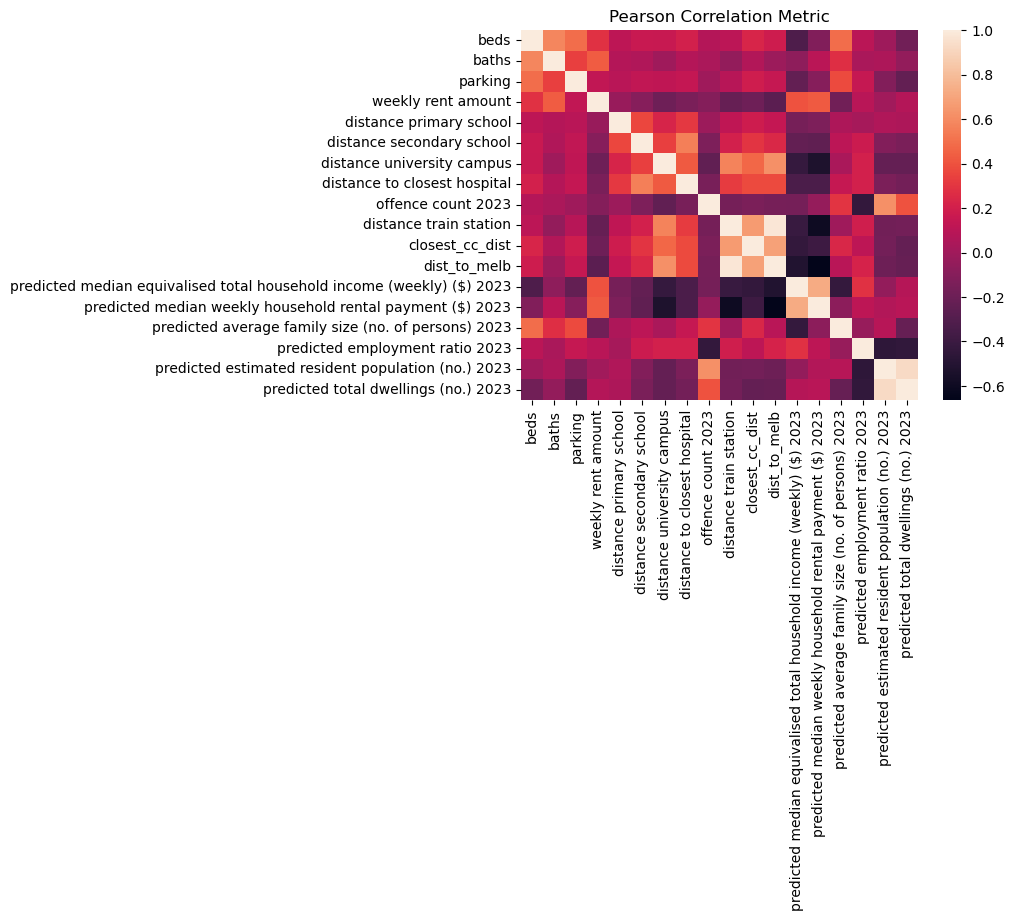

In [52]:
sns.heatmap(continous_data.corr())

plt.title('Pearson Correlation Metric')
plt.show()

# XGBoost Model

In [53]:
# split to training and test set
y = data["weekly rent amount"]
X = data.drop(["weekly rent amount"], axis=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [54]:
# standardise continous features
#scaler = StandardScaler()
#X_train_scaled = scaler.fit_transform(X_train)
#X_test_scaled = scaler.transform(X_test)

In [55]:
import xgboost as xgb
from sklearn.metrics import r2_score
model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=70, learning_rate=0.1, enable_categorical=True)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
r2 = r2_score(y_test, predictions)
r2

0.7276289080383811

In [56]:
from sklearn.metrics import mean_squared_error


# Calculate the mean squared error (MSE)
mse = mean_squared_error(y_test, predictions)

# Calculate the root mean squared error (RMSE)
rmse = np.sqrt(mse)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

Mean Squared Error (MSE): 16378.16664275312
Root Mean Squared Error (RMSE): 127.97721141966299


In [57]:
# create dataframe with true value, prediction and absolute error
pred_true_val = pd.DataFrame({"true rent price": y_test, "predicted price": predictions})
pred_true_val["error"] = np.abs(pred_true_val["true rent price"] - pred_true_val["predicted price"])

Most important features

In [58]:
# get of number of times a feature is used to split in tree across all trees 
booster = model.get_booster()
feature_scores = booster.get_score(importance_type='weight')
feature_scores_df = pd.DataFrame({"feature": list(feature_scores.keys()), "weight": list(feature_scores.values())})
feature_scores_df = feature_scores_df.sort_values(by=["weight"], ascending=False)
feature_scores_df.to_csv("../data/curated/top_features.csv", index=False)
feature_scores_df


,feature,weight
0,beds,424.0
3,distance primary school,395.0
9,distance train station,297.0
4,distance secondary school,289.0
7,distance to closest hospital,263.0
6,distance university campus,243.0
2,parking,198.0
1,baths,174.0
14,predicted median equivalised total household i...,165.0
12,closest_cc_dist,164.0


Text(0.5, 1.0, 'Histogram of true rent price')

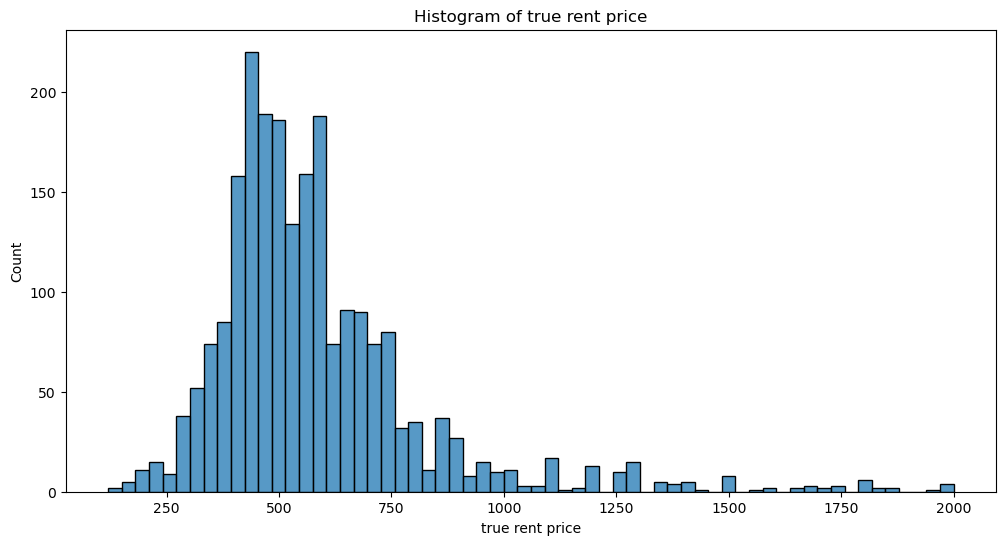

In [59]:
# distribution true rent price
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(pred_true_val["true rent price"])
ax.set_title("Histogram of true rent price")

Text(0.5, 1.0, 'Histogram of predicted rent price')

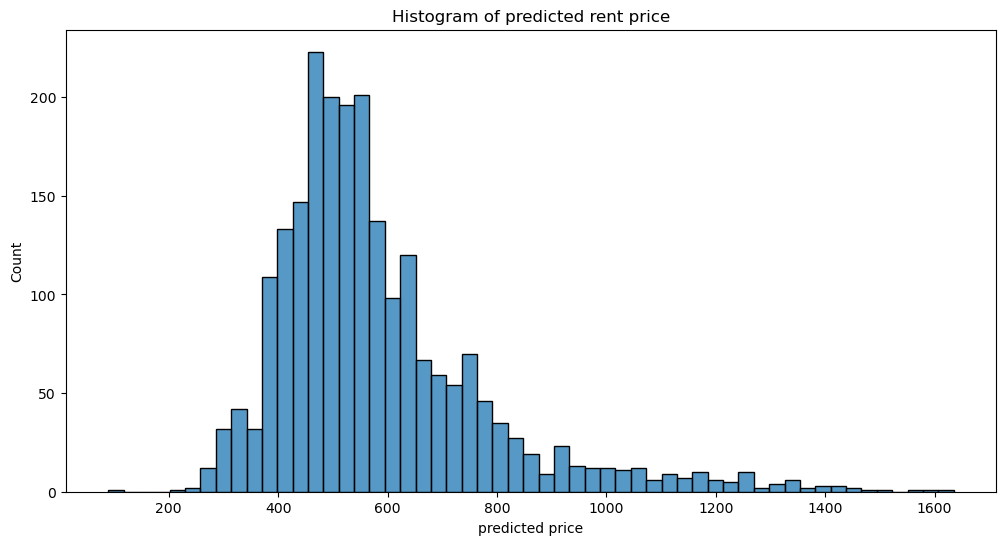

In [60]:
# distribution predicted price
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(pred_true_val["predicted price"])
ax.set_title("Histogram of predicted rent price")

Text(0.5, 1.0, 'Histogram of Errors')

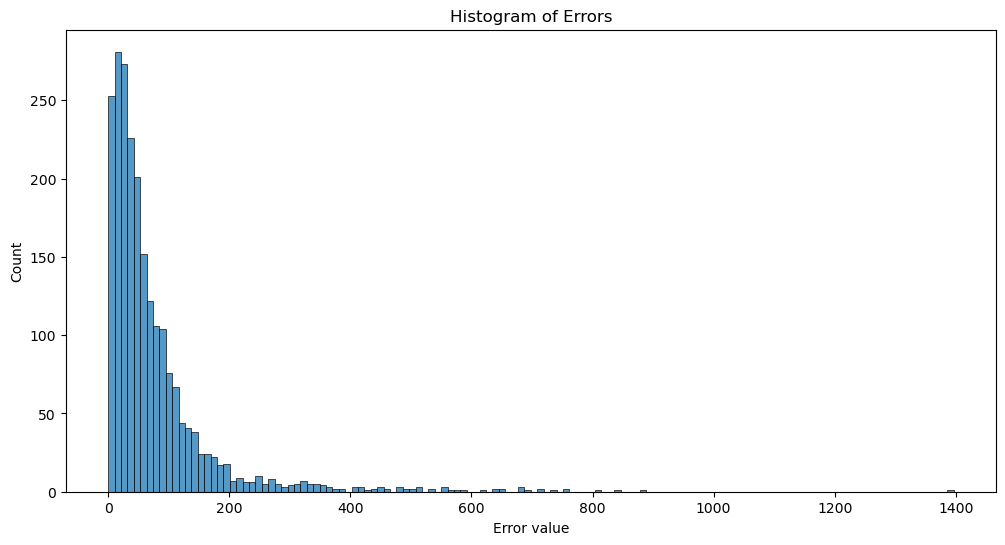

In [61]:
# Histogram of errors
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(pred_true_val["error"])
ax.set_xlabel("Error value")
ax.set_ylabel("Count")
ax.set_title("Histogram of Errors")

median error 46.6773681640625
25% percentile error 21.83709716796875
75% percentile error 91.13735961914062


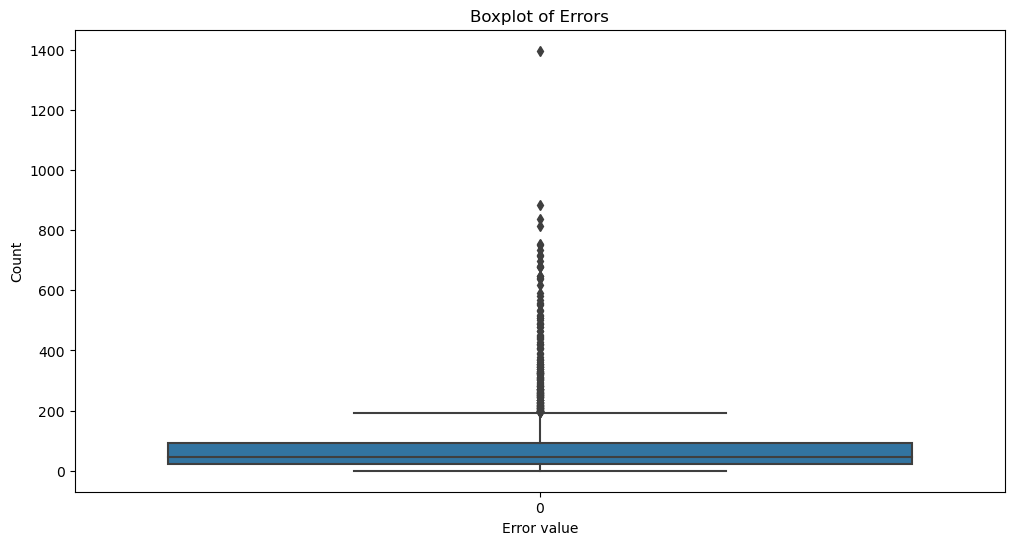

In [62]:
# Boxplot of errors
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(pred_true_val["error"])
ax.set_xlabel("Error value")
ax.set_ylabel("Count")
ax.set_title("Boxplot of Errors")
print(f"median error {np.median(pred_true_val['error'])}")
print(f"25% percentile error {np.percentile(pred_true_val['error'], 25)}")
print(f"75% percentile error {np.percentile(pred_true_val['error'], 75)}")

In [63]:
# average error for each rent price 
average_error_rent_price = pred_true_val.groupby("true rent price")["error"].mean().reset_index()
average_error_rent_price


,true rent price,error
0,120,486.251526
1,140,196.279175
2,165,86.116531
3,170,123.479660
4,180,124.913330
...,...,...
189,1847,1396.395111
190,1850,481.274292
191,1950,814.129395
192,1990,534.562866


Text(0.5, 1.0, 'True Rent Price vs Averate Prediction Error Bar Plot')

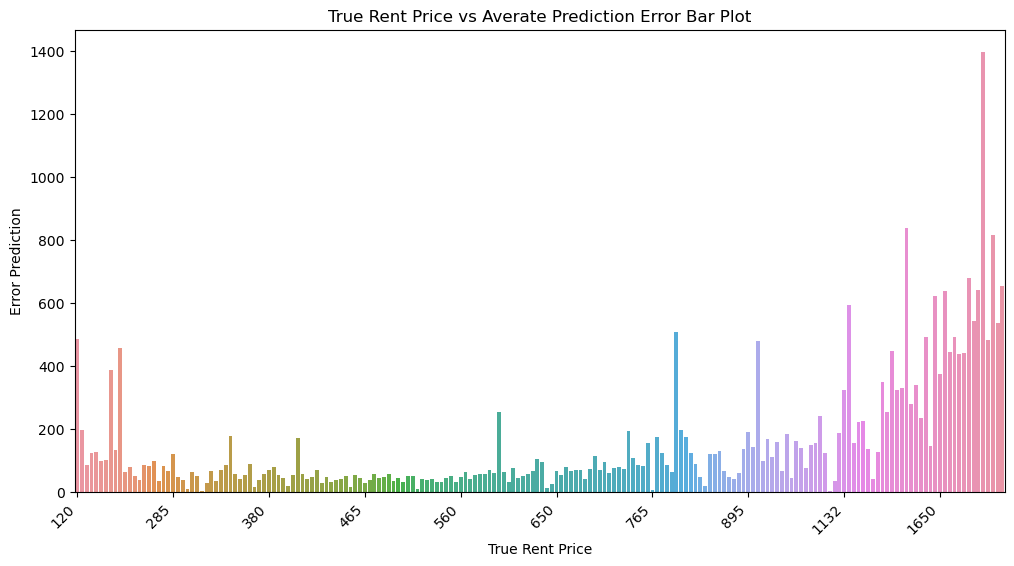

In [64]:
# Bar plot of average errors for rental price
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x="true rent price", y="error", data=average_error_rent_price, ax=ax)
tick_interval = 20  # Show every 20th label
x_values = list(average_error_rent_price["true rent price"])
visible_indices = range(0, len(x_values), tick_interval) 
visible_ticks = [x_values[i] for i in visible_indices]
ax.set_xticks(visible_indices)
ax.set_xticklabels(visible_ticks, rotation=45, ha='right')  # Rotate and align the labels
ax.set_xlabel("True Rent Price")
ax.set_ylabel("Error Prediction")
ax.set_title("True Rent Price vs Averate Prediction Error Bar Plot")
